In [331]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import odr
from scipy.optimize import curve_fit

In [332]:
# constants

wavelength = 632.8 * 10e-9 #m
gas_chamber_length = (17.46 - 2 * 3.2 -2) * 10e-3 #m assuming glass width of 3mm


In [333]:
#variables

pressure = 1 - (np.array([0, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46, 48, 50.5, 52, 54, 56, 58, 60, 62, 64, 66, 68, 70, 72, 74, 76, 78, 80, 82, 84, 86, 88, 90]) * 0.00986923) #convert from kPa to atm
intensity = np.array([52.153, 34.479, 54.067, 63.945, 56.711, 48.652, 16.915, 14.829, 36.860, 55.561, 69.997, 58.842, 35.649, 15.502, 16.253, 44.556, 64.983, 57.118, 42.048, 17.539, 14.765, 50.619, 60.336, 43.395, 30.128, 12.502, 26.511, 53.365, 61.155, 41.206, 17.654, 12.989, 31.580, 53.959, 61.173, 43.023, 17.527, 13.405, 26.138, 52.611, 60.635, 41.429, 20.470, 13.106]) #lux

#trial 2: np.array([10.243, 23.630, 32.838, 30.861, 22.697, 10.004, 16.500, 37.764, 16.379]) #lux

#trial 4:
#pressure = 1 - (np.array([0, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46, 48, 50.5, 52, 54, 56, 58, 60, 62, 64, 66, 68, 70, 72, 74, 76, 78, 80, 82, 84, 86, 88, 90]) * 0.00986923) #convert from kPa to atm
#intensity = np.array([52.153, 34.479, 54.067, 63.945, 56.711, 48.652, 16.915, 14.829, 36.860, 55.561, 69.997, 58.842, 35.649, 15.502, 16.253, 44.556, 64.983, 57.118, 42.048, 17.539, 14.765, 50.619, 60.336, 43.395, 30.128, 12.502, 26.511, 53.365, 61.155, 41.206, 17.654, 12.989, 31.580, 53.959, 61.173, 43.023, 17.527, 13.405, 26.138, 52.611, 60.635, 41.429, 20.470, 13.106]) #lux


In [334]:
#Errors

wavelength_error = 10 * 10e-9 #m
gas_chamber_length_error = 1
pressure_error = np.full_like(pressure, 0.00986923) #atm
intensity_error = np.array([2.798, 3.250, 2.098, 0.626, 2.455, 2.553, 1.042, 0.835, 2.293, 2.644, 1.060, 2.115, 3.445, 1.520, 1.787, 3.623, 0.904, 2.397, 2.265, 1.518, 1.333, 3.520, 1.227, 1.190, 2.723, 0.807, 3.069, 3.181, 0.807, 2.550, 1.711, 0.956, 2.174, 2.513, 0.707, 2.598, 2.059, 0.654, 2.227, 2.563, 1.199, 1.984, 2.189, 0.573])

#trial 4:
#intensity_error = np.array([2.798, 3.250, 2.098, 0.626, 2.455, 2.553, 1.042, 0.835, 2.293, 2.644, 1.060, 2.115, 3.445, 1.520, 1.787, 3.623, 0.904, 2.397, 2.265, 1.518, 1.333, 3.520, 1.227, 1.190, 2.723, 0.807, 3.069, 3.181, 0.807, 2.550, 1.711, 0.956, 2.174, 2.513, 0.707, 2.598, 2.059, 0.654, 2.227, 2.563, 1.199, 1.984, 2.189, 0.573])



Initial guesses:
I0 = 28.7475
k  = 0.000286909
Phase = 2.99652
C  = 12.502
initial_intensity = 22.5958 ± 1.8
k                 = 0.000294633 ± 1.9e-06
phase             = -2.87775 ± 0.2 rad
C                 = 16.5256 ± 2.2


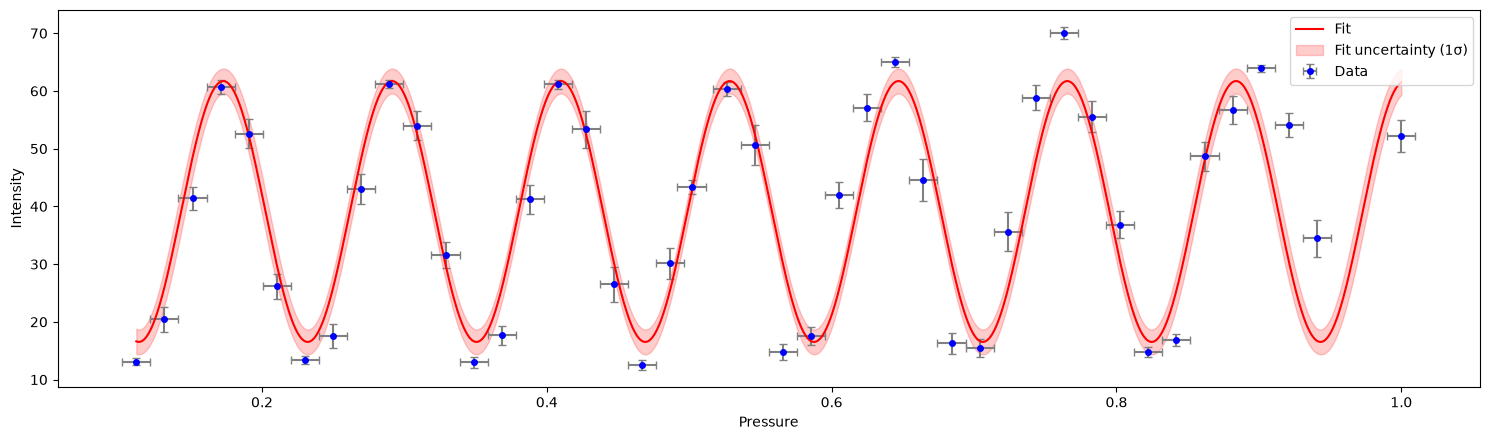

In [335]:

# Plotting

fig, ax = plt.subplots(figsize=(15, 4.5))

def model(pressure, initial_intensity, k, phase, C):
    angle = (
        4 * np.pi * gas_chamber_length * pressure * k / wavelength
        + phase
    )
    return initial_intensity * (1 + np.cos(angle)) + C

# Estimate initial intensity and offset
C_guess = np.min(I_sorted)
I0_guess = (np.max(I_sorted) - np.min(I_sorted)) / 2

if len(peaks) >= 2:
    pressure_period_guess = np.mean(np.diff(p_sorted[peaks]))
else:
    # Fallback: use FFT
    dp = np.mean(np.diff(p_sorted))
    fft = np.abs(np.fft.rfft(I_sorted - np.mean(I_sorted)))
    freqs = np.fft.rfftfreq(len(I_sorted), d=dp)

    pressure_period_guess = 1 / freqs[1:][np.argmax(fft[1:])]

# Convert pressure period to k
k_guess = wavelength / (
    2 * gas_chamber_length * pressure_period_guess
)

# Estimate phase from first data point
phase_guess = np.arccos(np.clip(
    (I_sorted[0] - C_guess) / (2 * I0_guess) - 1,
    -1, 1
))

p0 = [I0_guess, k_guess, phase_guess, C_guess]

print("Initial guesses:")
print(f"I0 = {I0_guess:.6g}")
print(f"k  = {k_guess:.6g}")
print(f"Phase = {phase_guess:.6g}")
print(f"C  = {C_guess:.6g}")


# Curve fitting
popt, pcov = curve_fit(
    model,
    pressure,
    intensity,
    p0=p0,
    bounds=([0, 0, -np.inf, -np.inf],
            [np.inf, np.inf, np.inf, np.inf]),
    x_scale=[max(abs(p0[0]), 1e-12), k_guess, 1.0, 1.0],
    max_nfev=20000,
)

# Extract fitted parameters
initial_intensity_fit, k_fit, phase_fit, C_fit = popt

# Parameter uncertainties
errors = np.sqrt(np.diag(pcov))

# Normalize phase
phase_fit = (phase_fit + np.pi) % (2 * np.pi) - np.pi

print(f"initial_intensity = {initial_intensity_fit:.6g} ± {errors[0]:.2g}")
print(f"k                 = {k_fit:.6g} ± {errors[1]:.2g}")
print(f"phase             = {phase_fit:.6g} ± {errors[2]:.2g} rad")
print(f"C                 = {C_fit:.6g} ± {errors[3]:.2g}")


# Generate fitted curve
p_plot = np.linspace(pressure.min(), pressure.max(), 2000)

y_fit = model(
    p_plot,
    initial_intensity_fit,
    k_fit,
    phase_fit,
    C_fit
)

J = np.column_stack((
    1 + np.cos(angle),

    -initial_intensity_fit * np.sin(angle)
    * (4 * np.pi * gas_chamber_length * p_plot / wavelength),

    -initial_intensity_fit * np.sin(angle),

    np.ones_like(p_plot)
))


# Propagate parameter uncertainties
fit_variance = np.einsum('ij,jk,ik->i', J, pcov, J)

fit_error = np.sqrt(np.maximum(fit_variance, 0))

# Experimental data with error bars
ax.errorbar(
    pressure,
    intensity,
    xerr=pressure_error,
    yerr=intensity_error,
    fmt='o',
    markersize=4,
    capsize=3,
    color='blue',
    ecolor='gray',
    label="Data"
)


# Fitted curve
ax.plot(
    p_plot,
    y_fit,
    color="red",
    label="Fit"
)


# Plot 1-sigma uncertainty band
ax.fill_between(
    p_plot,
    y_fit - fit_error,
    y_fit + fit_error,
    color="red",
    alpha=0.2,
    label="Fit uncertainty (1σ)"
)

ax.set_xlabel("Pressure")
ax.set_ylabel("Intensity")
ax.legend()

plt.tight_layout()
plt.show()


In [336]:
n_air = 1 + k_fit
print("n of air:", n_air)

n of air: 1.0002946327222955
